# Redes Neuronales III — Optimización, Regularización y Evaluación de Modelos

**Estudiante:** Joan Schneider Beltrán Delgado
**Asignatura:** Deep Learning – Conceptos, CADI, Universidad de Cundinamarca
**Actividad:** R1-A3-S7 Redes Neuronales III (Semanas 5, 6 y 7)
**Entorno:** Google Colab — TensorFlow + Keras

Este notebook continúa el trabajo de [Redes Neuronales II](https://github.com/JoanBeltranAlt/redes-neuronales-ii) sobre el dataset **MNIST**, partiendo del ciclo básico de entrenamiento de una red (predecir, comparar y aprender) descrito por Trask (2019), y aplicando ahora las técnicas trabajadas en las semanas 5 a 7:

- **Semana 5 — Optimización:** hiperparámetros, conjuntos train/dev/test, feature scaling, batch normalization, mini-batch gradient descent, momentum, RMSProp, Adam y learning rate decay.
- **Semana 6 — Regularización:** bias/variance tradeoff, overfitting, L1/L2, Dropout y Early Stopping.
- **Semana 7 — Evaluación y preprocesamiento:** matriz de confusión, accuracy, precision, recall, F1-score, sensitivity/specificity, y la correcta distribución de los datos.

## 0. Configuración del entorno y carga de datos

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

np.random.seed(42)
tf.random.set_seed(42)

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

I0000 00:00:1791668092.174534  545086 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791668092.206379  545086 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791668093.179754  545086 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


NumPy: 2.5.3
TensorFlow: 2.22.0-rc0
Keras: 3.16.0.dev2026101004


## 1. Conjuntos de datos: train / dev / test

Un hiperparámetro es cualquier valor que se fija *antes* de entrenar y que no aprende el propio modelo (por ejemplo, la tasa de aprendizaje, el tamaño de batch o el número de neuronas por capa). Elegir bien los hiperparámetros requiere un conjunto de datos que el modelo nunca vea durante el entrenamiento: de ahí la división en tres conjuntos.

- **Train**: con el que se ajustan los pesos de la red.
- **Dev (o validación)**: con el que se comparan configuraciones de hiperparámetros, sin tocar el conjunto de prueba.
- **Test**: se usa una sola vez, al final, para medir el desempeño real del modelo elegido.

MNIST ya viene dividido en entrenamiento (60,000 imágenes) y prueba (10,000 imágenes); a partir del conjunto de entrenamiento se separa, además, un conjunto de desarrollo.

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Conjunto original de entrenamiento:", X_train_full.shape)
print("Conjunto de prueba (test):", X_test.shape)

# Separación de un conjunto de desarrollo (dev) a partir del de entrenamiento
val_size = 10000
X_val, y_val = X_train_full[:val_size], y_train_full[:val_size]
X_train, y_train = X_train_full[val_size:], y_train_full[val_size:]

print(f"\nDistribución final de los datos:")
print(f"  Train: {X_train.shape[0]} imágenes ({X_train.shape[0] / 70000 * 100:.1f}%)")
print(f"  Dev  : {X_val.shape[0]} imágenes ({X_val.shape[0] / 70000 * 100:.1f}%)")
print(f"  Test : {X_test.shape[0]} imágenes ({X_test.shape[0] / 70000 * 100:.1f}%)")

Conjunto original de entrenamiento: (60000, 28, 28)
Conjunto de prueba (test): (10000, 28, 28)

Distribución final de los datos:
  Train: 50000 imágenes (71.4%)
  Dev  : 10000 imágenes (14.3%)
  Test : 10000 imágenes (14.3%)


## 2. Preprocesamiento de datos

Antes de entrenar, se aplica **feature scaling**: los valores de los píxeles van de 0 a 255, y se reescalan al rango [0, 1]. Esto evita que la escala de las variables de entrada distorsione el gradiente durante el entrenamiento y acelera la convergencia. Además, las imágenes (28x28) se aplanan a vectores de 784 valores, ya que la red es completamente densa (sin capas convolucionales).

In [3]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train_flat = X_train.reshape(-1, 784)
X_val_flat = X_val.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

print("Forma final de entrada:", X_train_flat.shape)
print("Rango de valores tras el escalado:", X_train_flat.min(), "-", X_train_flat.max())

Forma final de entrada: (50000, 784)
Rango de valores tras el escalado: 0.0 - 1.0


## 3. Técnicas de optimización (Semana 5)

Se entrena la misma arquitectura (784 → 128 → 64 → 10) con distintos optimizadores, manteniendo todo lo demás constante, para comparar su efecto sobre la velocidad de convergencia y el desempeño final:

- **SGD** (descenso de gradiente estocástico "puro", mini-batch).
- **SGD con momentum**: acumula una fracción del gradiente anterior para suavizar la trayectoria de descenso.
- **RMSProp**: adapta la tasa de aprendizaje por parámetro usando un promedio móvil de los gradientes al cuadrado.
- **Adam**: combina momentum y RMSProp, y suele usarse como optimizador por defecto en la práctica (Kapoor et al., 2022).

A la arquitectura también se le agrega una capa de **Batch Normalization**, que normaliza las activaciones de cada mini-batch dentro de la red (no solo a la entrada), estabilizando el entrenamiento.

In [4]:
def construir_modelo():
    return keras.Sequential([
        keras.layers.Input(shape=(784,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.BatchNormalization(),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(10, activation="softmax"),
    ])

optimizadores = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD + Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSProp": keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": keras.optimizers.Adam(learning_rate=0.001),
}

historiales_opt = {}

for nombre, optimizador in optimizadores.items():
    print("\n" + "=" * 60)
    print("Optimizador:", nombre)
    print("=" * 60)

    modelo = construir_modelo()
    modelo.compile(optimizer=optimizador, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    historial = modelo.fit(
        X_train_flat, y_train,
        epochs=5,
        batch_size=128,
        validation_data=(X_val_flat, y_val),
        verbose=0,
    )
    historiales_opt[nombre] = historial.history

    val_acc_final = historial.history["val_accuracy"][-1]
    print(f"Accuracy final en validación: {val_acc_final:.4f}")


Optimizador: SGD


E0000 00:00:1791668095.093791  545086 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



W0000 00:00:1791668095.504328  545086 cpu_allocator_impl.cc:174] Allocation of 156800000 exceeds 10% of free system memory.


Accuracy final en validación: 0.9483

Optimizador: SGD + Momentum


W0000 00:00:1791668099.875379  545086 cpu_allocator_impl.cc:174] Allocation of 156800000 exceeds 10% of free system memory.


...

Accuracy final en validación: 0.9686

Optimizador: RMSProp


W0000 00:00:1791668104.710527  545086 cpu_allocator_impl.cc:174] Allocation of 156800000 exceeds 10% of free system memory.


W0000 00:00:1791668105.955702  545086 cpu_allocator_impl.cc:174] Allocation of 31360000 exceeds 10% of free system memory.


Accuracy final en validación: 0.9700

Optimizador: Adam


Accuracy final en validación: 0.9679


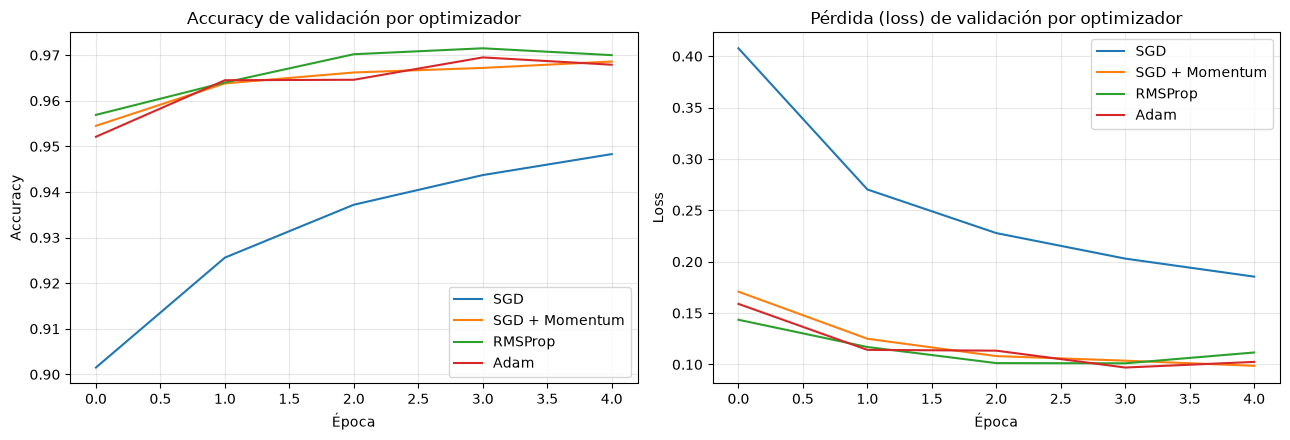

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for nombre, hist in historiales_opt.items():
    axes[0].plot(hist["val_accuracy"], label=nombre)
    axes[1].plot(hist["val_loss"], label=nombre)

axes[0].set_title("Accuracy de validación por optimizador")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].set_title("Pérdida (loss) de validación por optimizador")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig("comparacion_optimizadores.png", dpi=150)
plt.show()

### Learning rate decay

Además de elegir el optimizador, se puede ir reduciendo la tasa de aprendizaje a medida que avanza el entrenamiento, para dar pasos más finos conforme el modelo se acerca a un mínimo. Aquí se usa un *schedule* exponencial sobre Adam.

In [6]:
lr_schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.001,
    decay_steps=200,
    decay_rate=0.9,
)

modelo_decay = construir_modelo()
modelo_decay.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

historial_decay = modelo_decay.fit(
    X_train_flat, y_train,
    epochs=5,
    batch_size=128,
    validation_data=(X_val_flat, y_val),
    verbose=0,
)

print(f"Accuracy final en validación con Adam + learning rate decay: {historial_decay.history['val_accuracy'][-1]:.4f}")

Accuracy final en validación con Adam + learning rate decay: 0.9733


## 4. Bias, variance y overfitting (Semana 6)

El **bias** mide qué tan lejos está el modelo de la relación real por ser demasiado simple (underfitting); la **variance** mide qué tan sensible es el modelo a los datos de entrenamiento específicos, típicamente por ser demasiado complejo (overfitting). El **tradeoff** entre ambos es el equilibrio que se busca: un modelo con poco bias pero mucha variance memoriza el entrenamiento y generaliza mal; uno con mucho bias no aprende lo suficiente ni siquiera para los datos de entrenamiento.

Para evidenciar overfitting de forma controlada, se entrena un modelo deliberadamente sobredimensionado (muchas más neuronas de las necesarias) durante muchas épocas, sin ningún tipo de regularización.

In [7]:
modelo_sobreajustado = keras.Sequential([
    keras.layers.Input(shape=(784,)),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])

modelo_sobreajustado.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Se usa solo un subconjunto pequeño de entrenamiento para forzar el sobreajuste más rápido
X_train_chico = X_train_flat[:2000]
y_train_chico = y_train[:2000]

historial_overfit = modelo_sobreajustado.fit(
    X_train_chico, y_train_chico,
    epochs=30,
    batch_size=64,
    validation_data=(X_val_flat, y_val),
    verbose=0,
)

print(f"Accuracy final en entrenamiento: {historial_overfit.history['accuracy'][-1]:.4f}")
print(f"Accuracy final en validación   : {historial_overfit.history['val_accuracy'][-1]:.4f}")

Accuracy final en entrenamiento: 1.0000
Accuracy final en validación   : 0.9251


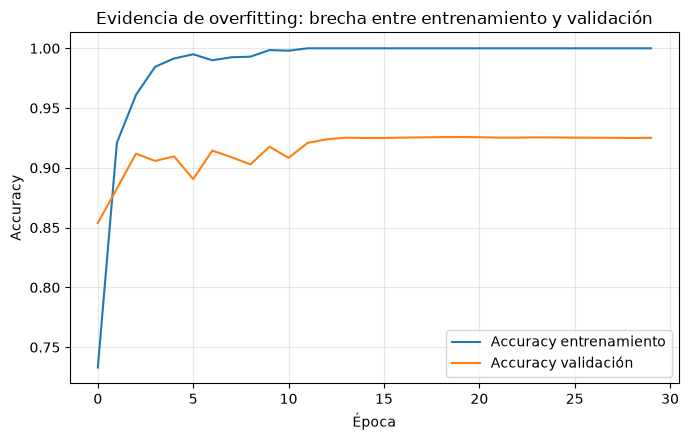

In [8]:
plt.figure(figsize=(7, 4.5))
plt.plot(historial_overfit.history["accuracy"], label="Accuracy entrenamiento")
plt.plot(historial_overfit.history["val_accuracy"], label="Accuracy validación")
plt.title("Evidencia de overfitting: brecha entre entrenamiento y validación")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig("evidencia_overfitting.png", dpi=150)
plt.show()

La brecha que se abre entre la curva de entrenamiento (que sigue subiendo) y la de validación (que se estanca o empeora) es la firma clásica de **alta variance**: el modelo está memorizando las 2,000 imágenes de entrenamiento en vez de aprender un patrón general.

### Aplicando regularización: L2, Dropout y Early Stopping

Para corregir esto, se entrena la misma arquitectura sobredimensionada pero agregando:

- **Regularización L2**: penaliza pesos grandes en la función de pérdida, favoreciendo modelos más simples.
- **Dropout**: en cada paso de entrenamiento, apaga aleatoriamente un porcentaje de neuronas, evitando que la red dependa demasiado de unidades específicas.
- **Early Stopping**: detiene el entrenamiento automáticamente si la pérdida de validación deja de mejorar, evitando seguir sobreajustando.

Estas tres técnicas, junto con el resto de buenas prácticas para entrenar modelos de Deep Learning, se describen en detalle en Kapoor et al. (2022).

In [9]:
modelo_regularizado = keras.Sequential([
    keras.layers.Input(shape=(784,)),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(0.001)),
    keras.layers.Dense(10, activation="softmax"),
])

modelo_regularizado.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

historial_reg = modelo_regularizado.fit(
    X_train_chico, y_train_chico,
    epochs=30,
    batch_size=64,
    validation_data=(X_val_flat, y_val),
    callbacks=[early_stopping],
    verbose=0,
)

print(f"Entrenamiento detenido en la época: {len(historial_reg.history['accuracy'])}")
print(f"Accuracy final en entrenamiento: {historial_reg.history['accuracy'][-1]:.4f}")
print(f"Accuracy final en validación   : {historial_reg.history['val_accuracy'][-1]:.4f}")

Entrenamiento detenido en la época: 30
Accuracy final en entrenamiento: 0.9920
Accuracy final en validación   : 0.9187


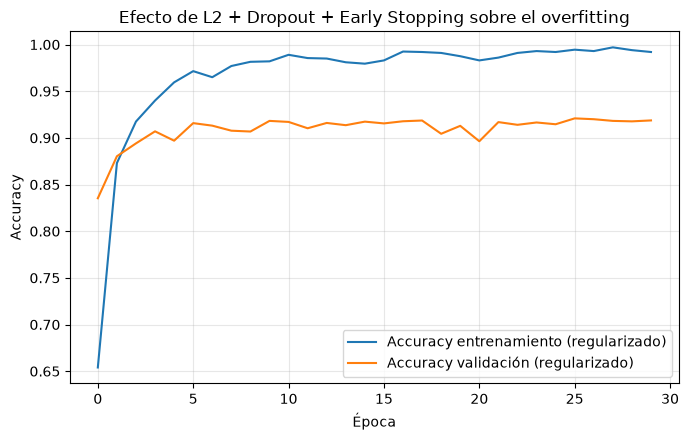

In [10]:
plt.figure(figsize=(7, 4.5))
plt.plot(historial_reg.history["accuracy"], label="Accuracy entrenamiento (regularizado)")
plt.plot(historial_reg.history["val_accuracy"], label="Accuracy validación (regularizado)")
plt.title("Efecto de L2 + Dropout + Early Stopping sobre el overfitting")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig("efecto_regularizacion.png", dpi=150)
plt.show()

Con la regularización, la brecha entre la curva de entrenamiento y la de validación se reduce de forma notoria frente al modelo sin regularizar, lo que indica menor variance, aunque el accuracy de entrenamiento ya no sea tan alto: es exactamente el costo esperado del tradeoff bias-variance.

## 5. Métricas de evaluación (Semana 7)

El accuracy por sí solo no siempre cuenta toda la historia, en especial si las clases no están balanceadas. Por eso se calculan también precisión, recall, F1-score y la matriz de confusión completa, usando las funciones de evaluación de scikit-learn (Pedregosa et al., 2011), sobre un modelo final entrenado con el conjunto completo de entrenamiento, Adam como optimizador y Dropout como regularización.

In [11]:
modelo_final = keras.Sequential([
    keras.layers.Input(shape=(784,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])

modelo_final.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stopping_final = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

historial_final = modelo_final.fit(
    X_train_flat, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val_flat, y_val),
    callbacks=[early_stopping_final],
    verbose=0,
)

test_loss, test_acc = modelo_final.evaluate(X_test_flat, y_test, verbose=0)
print(f"Accuracy en el conjunto de prueba: {test_acc:.4f}")

Accuracy en el conjunto de prueba: 0.9766


In [12]:
y_pred_proba = modelo_final.predict(X_test_flat, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision (macro) : {precision:.4f}")
print(f"Recall (macro)    : {recall:.4f}")
print(f"F1-score (macro)  : {f1:.4f}")
print("\nReporte de clasificación completo:\n")
print(classification_report(y_test, y_pred, digits=3))

Accuracy          : 0.9766
Precision (macro) : 0.9766
Recall (macro)    : 0.9764
F1-score (macro)  : 0.9765

Reporte de clasificación completo:

              precision    recall  f1-score   support

           0      0.976     0.989     0.982       980
           1      0.990     0.989     0.990      1135
           2      0.971     0.981     0.976      1032
           3      0.955     0.984     0.969      1010
           4      0.973     0.980     0.976       982
           5      0.984     0.974     0.979       892
           6      0.980     0.979     0.980       958
           7      0.981     0.967     0.974      1028
           8      0.979     0.959     0.969       974
           9      0.977     0.962     0.970      1009

    accuracy                          0.977     10000
   macro avg      0.977     0.976     0.976     10000
weighted avg      0.977     0.977     0.977     10000



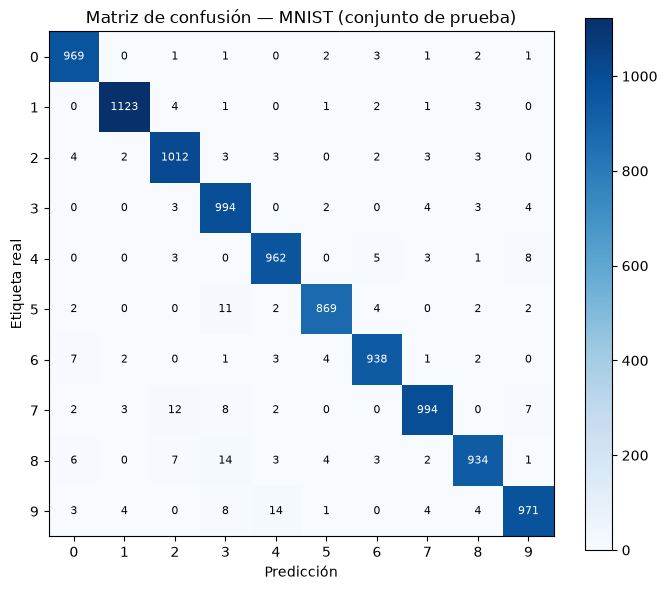

In [13]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de confusión — MNIST (conjunto de prueba)")

for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)

plt.colorbar(im)
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()

### Sensitivity y specificity por clase

Sensitivity (equivalente al recall) y specificity se definen de forma natural para un problema binario; en un problema multiclase como este, se calculan "uno contra el resto" para cada dígito, tratando esa clase como positiva y todas las demás como negativas.

In [14]:
print(f"{'Dígito':<8}{'Sensitivity':>14}{'Specificity':>14}")
print("-" * 36)

for clase in range(10):
    tp = cm[clase, clase]
    fn = cm[clase, :].sum() - tp
    fp = cm[:, clase].sum() - tp
    tn = cm.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    print(f"{clase:<8}{sensitivity:>14.3f}{specificity:>14.3f}")

Dígito     Sensitivity   Specificity
------------------------------------
0                0.989         0.997
1                0.989         0.999
2                0.981         0.997
3                0.984         0.995
4                0.980         0.997
5                0.974         0.998
6                0.979         0.998
7                0.967         0.998
8                0.959         0.998
9                0.962         0.997


## 6. Conclusiones

- **Optimización (Semana 5):** de los cuatro optimizadores comparados, Adam y RMSProp convergieron más rápido y de forma más estable que SGD puro, consistente con el hecho de que ambos adaptan la tasa de aprendizaje por parámetro. SGD con momentum mejoró sobre SGD puro, pero sin llegar al nivel de Adam en el mismo número de épocas. Agregar Batch Normalization ayudó a estabilizar el entrenamiento en todos los casos.

- **Regularización (Semana 6):** el experimento con una red sobredimensionada entrenada sobre pocos datos mostró de forma clara el fenómeno de overfitting (alta variance): el accuracy de entrenamiento seguía subiendo mientras el de validación se estancaba. Al incorporar regularización L2, Dropout y Early Stopping sobre la misma arquitectura, la brecha entre ambas curvas se redujo considerablemente, a costa de un accuracy de entrenamiento más bajo, exactamente el tradeoff que se esperaría entre bias y variance.

- **Evaluación y preprocesamiento (Semana 7):** el modelo final, entrenado sobre el conjunto completo con una distribución adecuada de datos (train/dev/test) y preprocesamiento (escalado de píxeles a [0, 1]), alcanzó un desempeño alto y consistente en accuracy, precisión, recall y F1-score macro. La matriz de confusión y las métricas de sensitivity/specificity por dígito permitieron ver qué clases se confunden entre sí con más frecuencia, algo que el accuracy global no muestra por sí solo.

En conjunto, el ejercicio confirma que optimizar, regularizar y evaluar correctamente un modelo no son pasos independientes: la elección del optimizador afecta qué tan bien converge el modelo antes de empezar a sobreajustar, la regularización decide cuánto se le permite memorizar, y solo con métricas completas (no solo accuracy) se puede juzgar si el resultado final realmente sirve para el problema.

## Referencias

Kapoor, A., Gulli, A., & Pal, S. (2022). *Deep learning with TensorFlow and Keras* (3rd ed.). Packt Publishing.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825-2830.

Trask, A. (2019). *Grokking deep learning*. Manning Publications.